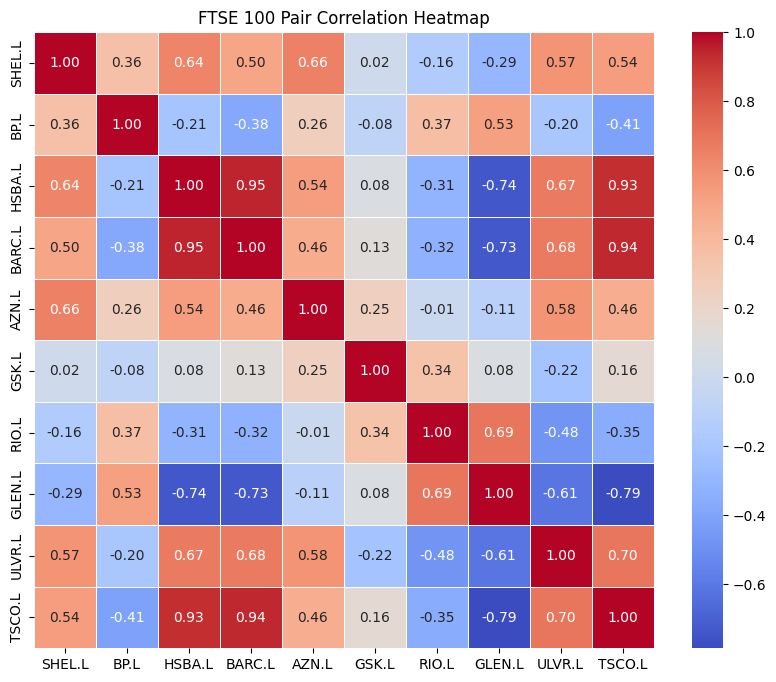


--- Top 10 Potential Pairs ---
BARC.L  HSBA.L    0.949133
HSBA.L  BARC.L    0.949133
BARC.L  TSCO.L    0.937782
TSCO.L  BARC.L    0.937782
        HSBA.L    0.926608
HSBA.L  TSCO.L    0.926608
ULVR.L  TSCO.L    0.698376
TSCO.L  ULVR.L    0.698376
RIO.L   GLEN.L    0.694330
GLEN.L  RIO.L     0.694330
dtype: float64


In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import os

# 1. Load the data
# We tell pandas the first column is our 'Date' index
data_path = os.path.join('..', 'data', 'ftse_prices.csv')
df = pd.read_csv(data_path, index_col=0, parse_dates=True)

# 2. Calculate the Correlation Matrix
# This tells us how much two stocks move in the same direction (-1 to 1)
corr_matrix = df.corr()

# 3. Create the Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('FTSE 100 Pair Correlation Heatmap')
plt.show()

# 4. Find the 'Top Hunters'
# We unstack the matrix and sort to find the highest correlations (excluding 1.0)
corr_pairs = corr_matrix.unstack().sort_values(ascending=False)
top_pairs = corr_pairs[corr_pairs < 1.0].head(10)

print("\n--- Top 10 Potential Pairs ---")
print(top_pairs)

In [3]:
from statsmodels.tsa.stattools import coint, adfuller
import statsmodels.api as sm

# 1. Define our pair
stock_y = df['HSBA.L']
stock_x = df['BARC.L']

# 2. Calculate Cointegration p-value
# Null Hypothesis: No cointegration. Low p-value (< 0.05) means REJECT null = Cointegrated!
score, pvalue, _ = coint(stock_y, stock_x)

# 3. Calculate the Hedge Ratio (Beta) using Linear Regression
X = sm.add_constant(stock_x) # Adds an intercept (alpha)
model = sm.OLS(stock_y, X).fit()
beta = model.params[1]

# 4. Generate the Spread
spread = stock_y - (beta * stock_x)

print(f"--- Cointegration Results for HSBA vs BARC ---")
print(f"P-Value: {pvalue:.4f}")
print(f"Hedge Ratio (Beta): {beta:.4f}")

if pvalue < 0.05:
    print("\n✅ SUCCESS: The pair is cointegrated! (p < 0.05)")
else:
    print("\n❌ FAIL: High p-value. This pair might just be 'correlated' but not 'cointegrated'.")

# 5. Visualize the Spread
plt.figure(figsize=(12, 6))
plt.plot(spread)
plt.axhline(spread.mean(), color='red', linestyle='--')
plt.title('Hedged Spread: HSBA - (Beta * BARC)')
plt.ylabel('Spread Value')
plt.show()

MissingDataError: exog contains inf or nans